# Actividades

In [9]:
import pandas as pd
datos = pd.read_csv("sensores_industriales.csv")
print(f"Primeras cinco filas: {datos.head()}")
print(f"Últimas tres filas: {datos.tail(3)}")
print(datos.shape)
print(datos.columns)
print(f"filas: {datos.shape[0]} | columnas: {datos.shape[1]}")

Primeras cinco filas:               fecha sensor         zona   turno  temperatura  humedad  \
0  2026-10-01 08:00    S01   Producción  Mañana         35.7     60.3   
1  2026-10-01 09:00    S02      Almacén  Mañana         38.0     60.9   
2  2026-10-01 10:00    S03  Laboratorio  Mañana         42.7     61.6   
3  2026-10-01 11:00    S04   Producción  Mañana         43.6     52.0   
4  2026-10-01 12:00    S05      Almacén  Mañana         45.7     59.3   

   consumo  vibración  presión  estado  
0    154.7       1.36     1.87  Normal  
1    171.4       1.64     2.01  Normal  
2    177.4       2.00     2.12  Normal  
3    193.8       2.29     2.24  Normal  
4    201.9       2.25     2.35  Normal  
Últimas tres filas:                 fecha sensor        zona   turno  temperatura  humedad  \
117  2026-10-06 05:00    S10  Producción   Noche         55.1     53.3   
118  2026-10-01 15:00    S08     Almacén  Mañana         50.8     56.1   
119  2026-10-03 08:00    S01  Producción  Mañana   

In [ ]:
# Ejercicio 2
print(datos.describe)
print(datos.isna().sum()) # ausentes
print(datos.duplicated().sum()) # duplicadas

<bound method NDFrame.describe of                 fecha sensor         zona   turno  temperatura  humedad  \
0    2026-10-01 08:00    S01   Producción  Mañana         35.7     60.3   
1    2026-10-01 09:00    S02      Almacén  Mañana         38.0     60.9   
2    2026-10-01 10:00    S03  Laboratorio  Mañana         42.7     61.6   
3    2026-10-01 11:00    S04   Producción  Mañana         43.6     52.0   
4    2026-10-01 12:00    S05      Almacén  Mañana         45.7     59.3   
..                ...    ...          ...     ...          ...      ...   
115  2026-10-06 03:00    S08      Almacén   Noche         47.2     57.8   
116  2026-10-06 04:00    S09  Laboratorio   Noche         51.2     55.2   
117  2026-10-06 05:00    S10   Producción   Noche         55.1     53.3   
118  2026-10-01 15:00    S08      Almacén  Mañana         50.8     56.1   
119  2026-10-03 08:00    S01   Producción  Mañana         38.8     59.3   

     consumo  vibración  presión  estado  
0      154.7       1.3

In [25]:
# Ejercicio 3
print(f"Valor medio de consumo {datos["consumo"].mean().round(2)}")
print(f"Temperatura mínima: {datos["temperatura"].min()}")
print(f"Humedad máxima: {datos["humedad"].max()}")

Valor medio de consumo 193.45
Temperatura mínima: 35.2
Humedad máxima: 64.9


In [26]:
print(datos["estado"])

0      Normal
1      Normal
2      Normal
3      Normal
4      Normal
        ...  
115    Normal
116    Normal
117    Alerta
118    Normal
119    Normal
Name: estado, Length: 120, dtype: object


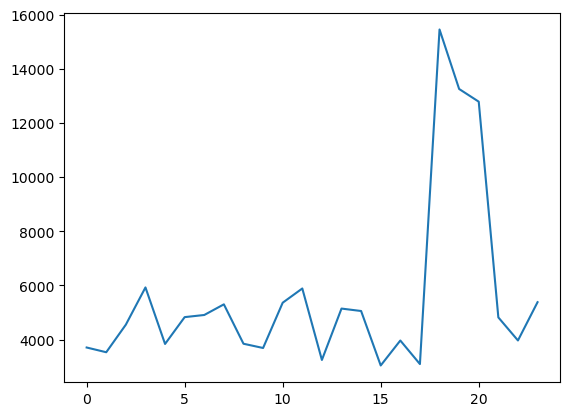

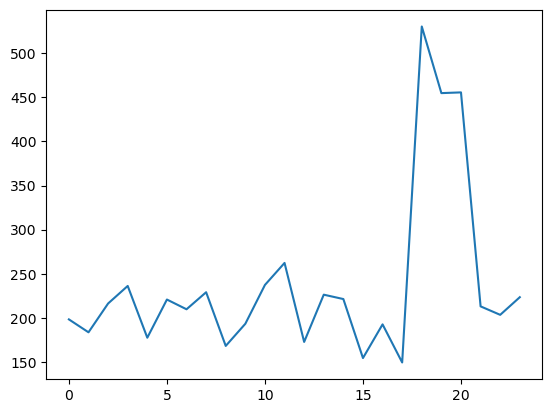

In [ ]:
import numpy 
import pandas
import matplotlib.pyplot as pypl

TRAFICO_ELEVADO = 12000
RESPUESTA_LENTA = 400

# Parte de generación de los datos
trafico = 50 + numpy.random.random(24) * 50
trafico[18:21] += 120 + numpy.random.random(3) * 60
tiempo_respuesta = 50 + trafico * 1.8 + numpy.random.random(24) * 40
horas = []
for i in range(24):
    horas.append(i)
simulaciones = pandas.DataFrame({
    "horas": horas,
    "tráfico": (trafico*60).astype("int"),
    "respuesta": tiempo_respuesta
})
simulaciones.to_csv("monitorizacion.csv",index=False)

# Análisis, gráficas y conclusiones
pypl.plot(simulaciones["horas"],simulaciones["tráfico"])
pypl.savefig("gráfica-horas-tráfico.jpg")
pypl.show()
pypl.plot(simulaciones["horas"],simulaciones["respuesta"])
pypl.savefig("gráfica-horas-tiempo-respuesta.jpg")
pypl.show()

# Generar json de registro de incidencias
registros_incidencias = simulaciones[(simulaciones["respuesta"]>RESPUESTA_LENTA) | (simulaciones["tráfico"]>TRAFICO_ELEVADO)]
registros_incidencias.to_json("incidencias.json",indent=4,force_ascii=False,orient="records")



## Conclusiones

Se observa un aumento del tiempo de respuesta del servidor entre las 18 y 21 h. Esto está ligado al aumento de peticiones/tráfico precisamente en ese rango de horas. Aunque aumenta mucho el tráfico y responde más lento, no se llega a caer el servidor porque siempre acaba dando una respuesta.